# 11 · Internal diffusion and effectiveness factors

A porous catalyst pellet is a reactor inside a reactor: reactant must diffuse in through the pores while
reacting on the walls, and if reaction is fast the interior sees little of it. The Thiele modulus compares
reaction to diffusion and the effectiveness factor says what fraction of the pellet is used. This notebook
computes both for the standard geometries, checks the closed forms against the pellet's differential
equation, shows the falsified kinetics of the diffusion-limited regime, and applies the Weisz-Prater test.

**What you will learn**
- compute Thiele moduli and effectiveness factors for the standard geometries
- interpret concentration profiles in pellets
- recognise falsified kinetics
- apply the Weisz-Prater criterion

**Before you start:** notebook 10  ·  **Time:** about 60 min

In [1]:
try:                      # on Google Colab (or anywhere engreact is missing): install it from GitHub
    import engreact
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engreact"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engreact import catalysis
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## The Thiele modulus and the effectiveness factor

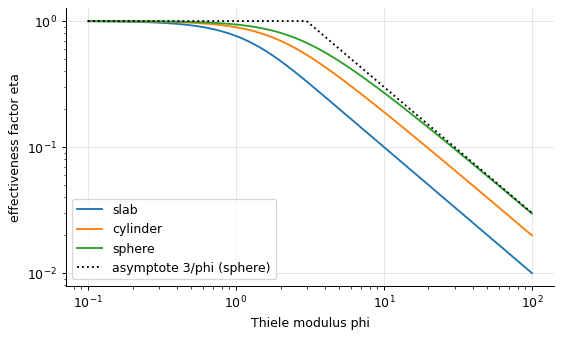

phi =   0.3: eta (sphere) = 0.994
phi =   1.0: eta (sphere) = 0.939
phi =   3.0: eta (sphere) = 0.672
phi =  10.0: eta (sphere) = 0.270
phi =  30.0: eta (sphere) = 0.097


In [2]:
phi = np.logspace(-1, 2, 200)
fig, ax = plt.subplots()
for geom in ("slab", "cylinder", "sphere"):
    ax.loglog(phi, catalysis.effectiveness_factor(phi, geom), label=geom)
ax.loglog(phi, np.minimum(1, 3 / phi), "k:", label="asymptote 3/phi (sphere)")
ax.set(xlabel="Thiele modulus phi", ylabel="effectiveness factor eta"); ax.legend(); plt.show()
for phi_ in (0.3, 1.0, 3.0, 10.0, 30.0):
    print(f"phi = {phi_:5.1f}: eta (sphere) = {catalysis.effectiveness_factor(phi_, 'sphere'):.3f}")

Below $\phi \approx 1$ the pellet is fully used; above about 3 the effectiveness factor falls as $3/\phi$ for a
sphere and the reaction happens in an outer shell. Doubling the pellet radius doubles $\phi$; at large $\phi$
that halves the rate per pellet volume. The three geometries agree closely when $\phi$ is defined with the
volume-to-surface ratio - the generalised modulus - which is why "the" curve is quoted.

## Inside the pellet

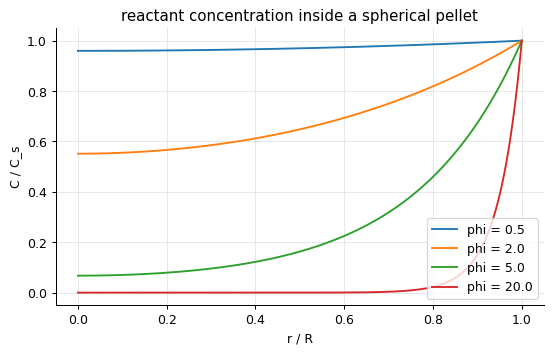

In [3]:
r = np.linspace(0, 1, 200)
fig, ax = plt.subplots()
for phi_ in (0.5, 2.0, 5.0, 20.0):
    ax.plot(r, catalysis.concentration_profile_sphere(phi_, r), label=f"phi = {phi_}")
ax.set(xlabel="r / R", ylabel="C / C_s", title="reactant concentration inside a spherical pellet"); ax.legend(); plt.show()

At $\phi$ = 20 the reactant penetrates a tenth of the radius: the core is dead weight. That is why industrial
catalysts are shaped as rings, trilobes and thin shells (eggshell catalysts) - to put the active material
where the reactant can reach it - and why crushing a catalyst to a fine powder in the laboratory gives a
different rate than the pellets in the plant.

## Checking the closed forms against the pellet equation

In [4]:
for geom in ("slab", "cylinder", "sphere"):
    for phi_ in (1.0, 5.0):
        print(f"{geom:<8} phi = {phi_}: closed form {catalysis.effectiveness_factor(phi_, geom):.4f}, BVP {catalysis.effectiveness_numerical(phi_, 1.0, geom):.4f}")
print("\nsecond-order reaction, sphere, phi = 5: eta =", round(catalysis.effectiveness_numerical(5.0, 2.0, "sphere"), 4), "(first order:", round(catalysis.effectiveness_factor(5.0, "sphere"), 4), ")")

slab     phi = 1.0: closed form 0.7616, BVP 0.7616
slab     phi = 5.0: closed form 0.2000, BVP 0.2000
cylinder phi = 1.0: closed form 0.8928, BVP 0.8928
cylinder phi = 5.0: closed form 0.3574, BVP 0.3574
sphere   phi = 1.0: closed form 0.9391, BVP 0.9391
sphere   phi = 5.0: closed form 0.4801, BVP 0.4801

second-order reaction, sphere, phi = 5: eta = 0.3972 (first order: 0.4801 )


The closed forms are first-order results; for any other order the pellet's boundary-value problem must be
solved numerically, and the library's solver reproduces the closed forms to four digits before being trusted
on the second-order case. A validated numerical tool is how one handles the kinetics that textbooks leave
as "it can be shown".

## Falsified kinetics

In [5]:
from engreact import kinetics
k_true, Ea_true, D_e, R_p = 1.0, 80e3, 1e-8, 2e-3
print("in the strong-diffusion regime:", catalysis.falsified_kinetics(2, Ea_true))
T = np.array([500, 525, 550, 575, 600.0])
k_T = kinetics.arrhenius(1e8, Ea_true, T)
phi_T = np.array([catalysis.thiele_modulus(k_, D_e, R_p / 3) * 3 for k_ in k_T])       # sphere modulus with R
r_obs = k_T * catalysis.effectiveness_factor(phi_T, "sphere")
Ea_app = kinetics.fit_arrhenius(T, r_obs)["Ea"]
print(f"phi from {phi_T[0]:.0f} to {phi_T[-1]:.0f}: the apparent activation energy is {Ea_app/1e3:.0f} kJ/mol against a true {Ea_true/1e3:.0f}")

in the strong-diffusion regime: {'apparent_order': 1.5, 'apparent_Ea': 40000.0}
phi from 13 to 66: the apparent activation energy is 42 kJ/mol against a true 80


When diffusion limits, the observed rate goes as $\sqrt{k}$: the apparent activation energy halves and the
apparent order moves towards one. An Arrhenius plot that bends to a lower slope at high temperature is the
classic signature of the onset of diffusion control. Kinetic parameters measured on large pellets are
falsified; the true ones need small particles or a correction.

## The Weisz-Prater criterion: is my measurement diffusion-free?

In [6]:
for R_p in (0.1e-3, 0.5e-3, 2e-3, 5e-3):
    C_wp = catalysis.weisz_prater(r_obs=1e-3, rho_c=1500.0, R=R_p, D_e=1e-7, C_s=20.0)      # 1 mmol/(kg s) observed
    print(f"pellet radius {R_p*1e3:4.1f} mm: C_WP = {C_wp:7.2f} -> " + ("negligible internal diffusion" if C_wp < 0.3 else "diffusion limited"))

pellet radius  0.1 mm: C_WP =    0.01 -> negligible internal diffusion
pellet radius  0.5 mm: C_WP =    0.19 -> negligible internal diffusion
pellet radius  2.0 mm: C_WP =    3.00 -> diffusion limited
pellet radius  5.0 mm: C_WP =   18.75 -> diffusion limited


Weisz and Prater's criterion uses only observable quantities - the measured rate, the pellet size, the
effective diffusivity and the surface concentration - to decide whether the measurement is
diffusion-free: $C_{WP} = \eta\phi^2 \ll 1$. It is the first thing a referee asks about a reported rate law
for a solid catalyst, and the calculation takes one line.

## Inside the algorithm: the sphere effectiveness factor

In [7]:
phi_ = 3.0
print("by hand: eta =", 3 / phi_**2 * (phi_ / np.tanh(phi_) - 1), "; library:", catalysis.effectiveness_factor(phi_, "sphere"))

by hand: eta = 0.6716364899803559 ; library: 0.6716364899803559


## Exercises
1. A first-order reaction (k = 5 1/s per pellet volume, D_e = 2e-9 m2/s) runs on spherical pellets. Find the pellet radius for eta = 0.9 and for eta = 0.5, and the rate per unit reactor volume in each case if the bed void fraction is 0.4. Which would you choose given the pressure-drop result of notebook 04?
2. An eggshell catalyst puts the active phase in a 0.2 mm shell on 3 mm pellets. Treating the shell as a slab of half-thickness 0.1 mm, compare its effectiveness factor with that of a uniformly impregnated 3 mm sphere for the kinetics above.
3. **Implement it yourself:** solve the slab pellet equation y'' = phi^2 y with solve_bvp and compute eta from the flux at the surface; compare with tanh(phi)/phi for phi = 2.